# Frente estatística – ARIMA / ARIMAX / SARIMAX (T+1 no WIN)

Responsável: **Itamar da Silva Rocha Filho** · Plano: [`planos/PLANO_FRENTES_02.11.md`](../../planos/PLANO_FRENTES_02.11.md), Seções 3.1 e 4.

| Etapa | O que faz | Saída em `resultados/estatistico/` |
|---|---|---|
| A | Prepara dados e o modelo | – |
| B | Grade candle × janela na validação (2024), ARIMA(1,0,1) | `grade_val.csv`, 3 heatmaps, 12 previsões |
| C | Regra de operação (limiar × TP × SL) na validação | `regras_val.csv` |
| D | Variantes ARIMAX / SARIMA / SARIMAX na melhor combinação + correlação WIN × WDO | `variante_val.csv`, `correlacao_win_wdo.png` |
| E | Congela tudo e roda o teste (01/2025 → 03/2026) **uma vez** | `config_final.json`, `teste_final.csv` |
| F | Gráficos finais e resumo | `curva_capital_teste.png`, `previsto_vs_real_teste.png`, `resumo.md` |
| G (extra) | Parâmetros estimados e bandas de previsão (descritivo, depois do teste) | `parametros_estimados.csv`, `bandas_*` |

Tudo o que é comum às três frentes (bases, janelas, métricas, simulação) vem do `tt1_comum.py`, importado sem alterações.

## Etapa A – Preparação

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
warnings.simplefilter("ignore", ConvergenceWarning); warnings.simplefilter("ignore", ValueWarning)
warnings.simplefilter("ignore", RuntimeWarning); warnings.simplefilter("ignore", UserWarning)

# PASTA = raiz do repositório (onde está o tt1_comum.py). Local: sobe a partir da pasta do notebook. Colab: /content/...
_cands = [Path.cwd(), *Path.cwd().parents, Path("/content/data_science_no_mercado_financeiro")]
PASTA = str(next(p for p in _cands if (p / "tt1_comum.py").exists()))
sys.path.append(PASTA)
import tt1_comum as t

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
FRENTE = "estatistico"
SAIDA = f"{PASTA}/resultados/{FRENTE}"
Path(f"{SAIDA}/previsoes").mkdir(parents=True, exist_ok=True)

df15, s15 = t.montar_base(win, wdo, "15min")
print(f"15min: {len(df15)} linhas, s = {s15}")          # pronto quando: ~45 mil linhas e s = 38

15min: 45057 linhas, s = 38


Modelo da frente (Seção 3.1 do plano). O `ArimaT1` estima os parâmetros no treino; no bloco de previsão só
incorpora as novas observações (`extend`), então a previsão de *t+1* usa apenas dados até *t*, sem re-estimar.

In [2]:
class ArimaT1:
    '''ARIMA/ARIMAX/SARIMAX: estima no treino; no teste só incorpora as novas observações (extend),
    então a previsão de t+1 usa só dados até t, sem re-estimar parâmetros.'''
    usa_y_teste = True
    def __init__(self, order=(1, 0, 1), seasonal_order=(0, 0, 0, 0), usa_x=False):
        self.kw = dict(order=order, seasonal_order=seasonal_order); self.usa_x = usa_x
    def fit(self, X, y):
        self.res = SARIMAX(y.values, exog=X.values if self.usa_x else None, **self.kw).fit(disp=False)
        return self
    def predict(self, X, y):
        return self.res.extend(y.values, exog=X.values if self.usa_x else None).predict()

MODELO, FABRICA, FEATS = "arima", ArimaT1, "LAGS"

# Erro-padrão e estatística t da esperança: mesma definição da frente de ML (frentes/ml/frente_ml.ipynb),
# para a tabela de comparação ficar homogênea. Só informativo: o critério de escolha continua o do plano.
def estat(ops):
    x = ops[ops.lado != 0].pontos
    if len(x) < 30:
        return dict(esperanca_pts=np.nan, ep_pts=np.nan, t_stat=np.nan)
    ep = x.std() / np.sqrt(len(x))
    return dict(esperanca_pts=x.mean(), ep_pts=ep, t_stat=x.mean() / ep)

def regras_com_t(prev, custo_pts=5):
    '''t.grade_regras (mesma ordem: maior esperança primeiro) + erro-padrão e t de cada regra.'''
    g = t.grade_regras(prev, custo_pts=custo_pts).reset_index(drop=True)
    st = [estat(t.simular(prev, r.limiar, None if pd.isna(r.tp_mult) else r.tp_mult,
                          None if pd.isna(r.sl_mult) else r.sl_mult, custo_pts)) for r in g.itertuples()]
    g[["ep_pts", "t_stat"]] = pd.DataFrame(st)[["ep_pts", "t_stat"]]
    return g

## Etapa B – Grade candle × janela na validação (Q1, Q2)

In [3]:
t0 = time.time()
tab = t.rodar_grade(win, wdo, MODELO, FABRICA, FEATS, SAIDA)          # 12 combinações, período 2024
print(f"grade completa em {time.time() - t0:.0f}s")
extra = []
for r in tab.itertuples():
    p = pd.read_csv(f"{SAIDA}/previsoes/WIN_{r.candle}_{r.janela_meses}m_{MODELO}_val.csv", index_col=0, parse_dates=True)
    st = estat(t.simular(p, custo_pts=5))
    extra.append(dict(sim_ep_pts=st["ep_pts"], sim_t_stat=st["t_stat"]))
tab = pd.concat([tab, pd.DataFrame(extra)], axis=1)
tab.to_csv(f"{SAIDA}/grade_val.csv", index=False)
t.heatmap(tab, "TheilU", f"{MODELO}: Theil U (validação 2024)", f"{SAIDA}/heatmap_theilU.png", menor_melhor=True)
t.heatmap(tab, "acc_dir", f"{MODELO}: acurácia direcional", f"{SAIDA}/heatmap_acuracia.png", fmt=".3f")
t.heatmap(tab, "sim_esperanca_pts", f"{MODELO}: esperança por operação (pts)", f"{SAIDA}/heatmap_esperanca.png", fmt=".2f")
cols = ["candle", "janela_meses", "tempo_s", "n", "TheilU", "R2_oos", "acc_dir", "corr",
        "sim_n_ops", "sim_taxa_acerto", "sim_esperanca_pts", "sim_ep_pts", "sim_t_stat", "sim_fator_lucro"]
tab[cols].round(4)

arima 1min 1m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0, 'R2_oos': -0.0001, 'acc_dir': 0.5112, 'corr': 0.0059} 4s


arima 1min 3m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0003, 'R2_oos': -0.0006, 'acc_dir': 0.5139, 'corr': 0.003} 11s


arima 1min 6m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0002, 'R2_oos': -0.0005, 'acc_dir': 0.5157, 'corr': 0.0066} 12s


arima 1min 12m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0001, 'R2_oos': -0.0003, 'acc_dir': 0.5164, 'corr': 0.0056} 19s


arima 15min 1m {'n': 9268.0, 'RMSE': 0.1224, 'MAE': 0.0855, 'TheilU': 1.0014, 'R2_oos': -0.0029, 'acc_dir': 0.5011, 'corr': -0.0176} 0s


arima 15min 3m {'n': 9268.0, 'RMSE': 0.1223, 'MAE': 0.0854, 'TheilU': 1.0008, 'R2_oos': -0.0015, 'acc_dir': 0.5062, 'corr': -0.0113} 1s


... (3 outputs left out)

arima 60min 3m {'n': 2254.0, 'RMSE': 0.2302, 'MAE': 0.1625, 'TheilU': 1.0068, 'R2_oos': -0.0137, 'acc_dir': 0.4745, 'corr': -0.0582} 0s


arima 60min 6m {'n': 2254.0, 'RMSE': 0.229, 'MAE': 0.1616, 'TheilU': 1.0016, 'R2_oos': -0.0032, 'acc_dir': 0.5022, 'corr': -0.0118} 0s


arima 60min 12m {'n': 2254.0, 'RMSE': 0.2292, 'MAE': 0.1618, 'TheilU': 1.0022, 'R2_oos': -0.0045, 'acc_dir': 0.4781, 'corr': -0.0365} 0s
grade completa em 59s


,candle,janela_meses,tempo_s,n,TheilU,R2_oos,acc_dir,corr,sim_n_ops,sim_taxa_acerto,sim_esperanca_pts,sim_ep_pts,sim_t_stat,sim_fator_lucro
0,1min,1,4.2,141216,1.0000,-0.0001,0.5112,0.0059,141216,0.4084,-4.7086,0.1121,-42.0057,0.7251
1,1min,3,11.4,141216,1.0003,-0.0006,0.5139,0.0030,141216,0.4104,-4.7006,0.1121,-41.9337,0.7253
2,1min,6,11.6,141216,1.0002,-0.0005,0.5157,0.0066,141216,0.4120,-4.5761,0.1121,-40.8242,0.7315
3,1min,12,18.6,141216,1.0001,-0.0003,0.5164,0.0056,141216,0.4126,-4.5385,0.1121,-40.4891,0.7333
4,15min,1,0.3,9268,1.0014,-0.0029,0.5011,-0.0176,9268,0.4744,-3.2774,1.6363,-2.0030,0.9423
5,15min,3,1.0,9268,1.0008,-0.0015,0.5062,-0.0113,9268,0.4789,-5.2541,1.6364,-3.2108,0.9090
6,15min,6,1.2,9268,1.0005,-0.0010,0.4984,-0.0087,9268,0.4699,-5.2929,1.6364,-3.2346,0.9084
7,15min,12,1.2,9268,1.0001,-0.0002,0.4945,-0.0090,9268,0.4678,-7.1229,1.6362,-4.3533,0.8787
8,60min,1,0.1,2254,1.0257,-0.0521,0.4960,-0.0393,2254,0.4787,-10.8962,6.2030,-1.7566,0.9006
9,60min,3,0.2,2254,1.0068,-0.0137,0.4745,-0.0582,2254,0.4592,-18.6957,6.1975,-3.0166,0.8355


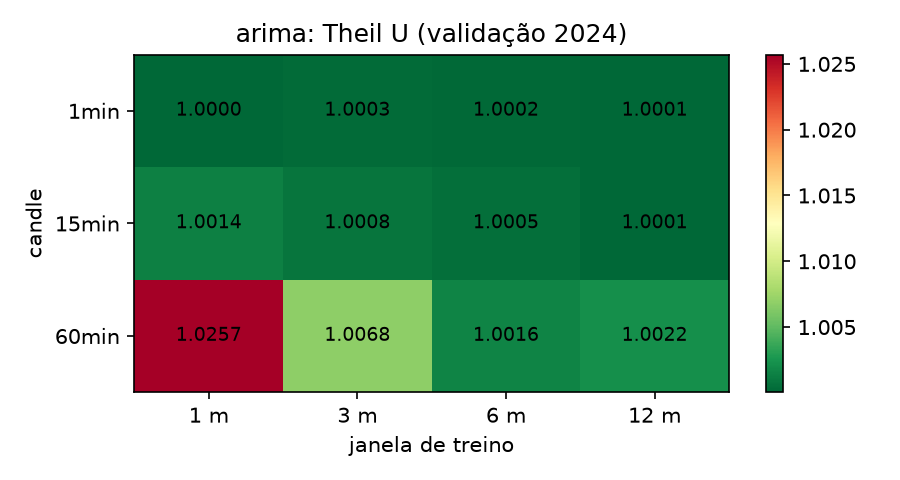

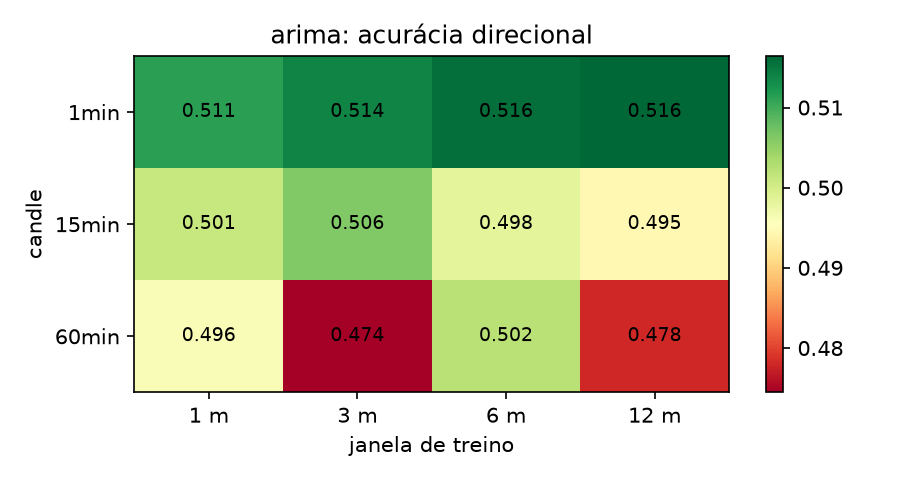

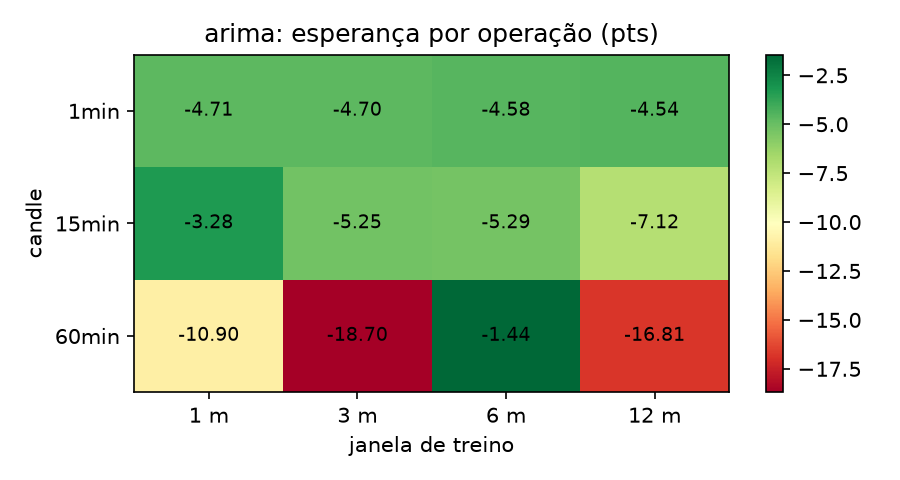

In [4]:
from IPython.display import Image, display
for h in ["theilU", "acuracia", "esperanca"]:
    display(Image(f"{SAIDA}/heatmap_{h}.png"))

In [5]:
melhor = tab.sort_values(["sim_esperanca_pts", "TheilU"], ascending=[False, True]).iloc[0]
CANDLE, JANELA = melhor.candle, int(melhor.janela_meses)
print(f"Melhor combinação na validação: candle {CANDLE}, janela {JANELA} meses | "
      f"esperança {melhor.sim_esperanca_pts:.2f} pts/op | Theil U {melhor.TheilU:.4f} | acurácia {melhor.acc_dir:.3f}")
print(f"Combinações com Theil U < 1: {(tab.TheilU < 1).sum()} de {len(tab)} | com R²_oos > 0: {(tab.R2_oos > 0).sum()}")
print(f"Correlação (Spearman) acurácia × esperança entre as 12 combinações: "
      f"{tab.acc_dir.corr(tab.sim_esperanca_pts, method='spearman'):.2f}")

Melhor combinação na validação: candle 60min, janela 6 meses | esperança -1.44 pts/op | Theil U 1.0016 | acurácia 0.502
Combinações com Theil U < 1: 0 de 12 | com R²_oos > 0: 0
Correlação (Spearman) acurácia × esperança entre as 12 combinações: 0.75


**Leitura da grade (Q1, Q2)**

- **Nenhuma das 12 combinações bate o naive.** O Theil U fica entre 1,0000 e 1,0257 e o R²_oos é negativo em todas. O ARIMA(1,0,1) estima coeficientes quase nulos, porque o retorno de um candle do WIN se comporta como ruído. O pouco que ele prevê soma erro ao naive.
- **Janela curta piora.** Com 1 mês de treino os coeficientes ficam mais ruidosos (60 min × 1m: Theil U 1,026). Com 12 meses o modelo encolhe para zero e o Theil U converge para 1.
- **Em 1 min o custo é tudo.** A esperança é ≈ −4,6 pts/op, praticamente o próprio custo de 5 pts, então o ganho bruto do modelo é ≈ 0. A taxa de acerto cai para ~41% porque, em candles pequenos, os 5 pts de custo transformam movimentos mínimos em perda.
- **Escolha: 60 min × 6 meses**, a única combinação com fator de lucro perto de 1 (0,986) e esperança de −1,44 pts/op. Ressalva: os vizinhos (60 min × 3m: −18,7; × 12m: −16,8) mostram que em 60 min o resultado oscila muito. São só 2.254 candles no ano, e a diferença entre combinações é em boa parte ruído.

## Etapa C – Regra de operação na validação (Q3, Q4)

In [6]:
prev_val = pd.read_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_{MODELO}_val.csv", index_col=0, parse_dates=True)
regras = regras_com_t(prev_val, custo_pts=5)
regras.to_csv(f"{SAIDA}/regras_val.csv", index=False)   # regras do modelo BASE (convenção comum)
regra = regras.iloc[0]                       # maior esperança por operação
print(f"{len(regras)} regras testadas. Melhor: limiar q={regra.limiar_q} ({regra.limiar:.4f}%), "
      f"TP={regra.tp_mult}, SL={regra.sl_mult} -> esperança {regra.esperanca_pts:.2f} pts/op, "
      f"(± {regra.ep_pts:.1f}, t = {regra.t_stat:.2f}), fator de lucro {regra.fator_lucro:.3f}, {int(regra.n_ops)} operações")
print(f"Regras com esperança > 0 e fator de lucro > 1: {((regras.esperanca_pts > 0) & (regras.fator_lucro > 1)).sum()}")
print(f"Correlação (Spearman) taxa de acerto × esperança entre as regras: "
      f"{regras.taxa_acerto.corr(regras.esperanca_pts, method='spearman'):.2f}")
regras.head(10).round(4)

36 regras testadas. Melhor: limiar q=0.9 (0.0159%), TP=2.0, SL=1.0 -> esperança 1.39 pts/op, (± 18.1, t = 0.08), fator de lucro 1.012, 226 operações
Regras com esperança > 0 e fator de lucro > 1: 2
Correlação (Spearman) taxa de acerto × esperança entre as regras: 0.48


,limiar_q,limiar,tp_mult,sl_mult,custo_pts,n_ops,taxa_acerto,ganho_medio,perda_media,payoff,esperanca_pts,fator_lucro,resultado_pts,resultado_R,drawdown_max_pts,ep_pts,t_stat
0,0.9,0.0159,2.0,1.0,5,226,0.4867,234.7101,-221.7788,1.0583,1.3874,1.0123,313.5444,62.7089,4808.5640,18.0845,0.0767
1,0.9,0.0159,NaN,1.0,5,226,0.4867,233.4545,-221.7788,1.0526,0.7763,1.0069,175.4341,35.0868,4829.3756,18.3225,0.0424
2,0.0,0.0000,2.0,NaN,5,2254,0.4938,207.1931,-208.3289,0.9945,-1.1154,0.9892,-2514.1088,-502.8218,22161.2203,5.8746,-0.1899
3,0.0,0.0000,NaN,NaN,5,2254,0.4876,212.1156,-208.7942,1.0159,-1.4374,0.9863,-3240.0000,-648.0000,23395.0000,6.2038,-0.2317
4,0.9,0.0159,2.0,2.0,5,226,0.5000,239.8005,-248.5444,0.9648,-2.1725,0.9822,-490.9746,-98.1949,7130.0447,20.3033,-0.1070
5,0.9,0.0159,1.0,1.0,5,226,0.5000,219.9996,-226.5140,0.9712,-2.2549,0.9799,-509.6100,-101.9220,5073.4705,17.0988,-0.1319
6,0.0,0.0000,1.0,NaN,5,2254,0.5297,179.9143,-211.7500,0.8497,-2.3968,0.9755,-5402.3130,-1080.4626,26487.0706,5.3155,-0.4509
7,0.0,0.0000,NaN,2.0,5,2254,0.4809,211.5959,-206.1691,1.0263,-3.1526,0.9700,-7105.9842,-1421.1968,22506.7252,5.9736,-0.5278
8,0.9,0.0159,1.0,2.0,5,226,0.5265,220.6408,-257.6994,0.8562,-3.5495,0.9704,-802.1777,-160.4355,6886.1076,19.2397,-0.1845
9,0.9,0.0159,2.0,NaN,5,226,0.5000,239.8005,-252.3874,0.9501,-4.0599,0.9672,-917.5424,-183.5085,7879.1885,20.6589,-0.1965


**Leitura da regra (Q3, Q4 na validação)**

- Só 2 das 36 regras ficam com esperança > 0 e fator de lucro > 1, ambas com **limiar no quantil 90% e stop de 1× a volatilidade**. A melhor dá +1,39 pts/op em 226 operações. O erro-padrão dessa média é ≈ 18 pts (t ≈ 0,08), então o resultado **não se distingue de zero**.
- **Acertar mais não é ganhar mais.** A regra com maior taxa de acerto (opera sempre + TP 1×: 53,0%) tem esperança de −2,40 pts/op. O take profit corta os ganhos (ganho médio 180 pts contra perda média de 212 pts). A correlação entre taxa de acerto e esperança nas 36 regras é só 0,48.

## Etapa D – Variantes: ARIMAX, SARIMA e SARIMAX

Rodadas na validação (2024), com o mesmo walk-forward, métricas e simulação da grade.

| Variante | Especificação | Pergunta que responde |
|---|---|---|
| `arimax` | ARIMA(1,0,1) + `ret_wdo_lag1` (WDO em *t*, nunca em *t+1*) | O dólar do candle atual ajuda a prever o índice do próximo? |
| `sarima_s{k}` | ARIMA(1,0,1)×(1,0,0)ₖ, sem exógena | Existe padrão "mesmo horário do pregão anterior"? |
| `sarimax_s{k}` | ARIMA(1,0,1)×(1,0,0)ₖ + `ret_wdo_lag1` | As duas coisas juntas (especificação do plano) |

**Sobre o período sazonal.** O `montar_base` devolve `s` = candles por pregão (38 em 15 min, 10 em 60 min),
calculado **antes** de descartar o último candle de cada dia (que não tem alvo). Na série que o modelo
efetivamente vê, cada pregão tem `s − 1` linhas (verificado abaixo), então a defasagem `s` aponta para o
candle seguinte ao "mesmo horário de ontem". Rodamos o SARIMAX com os dois valores: o `s` do plano e o
`s` efetivo. O SARIMA isolado usa o `s` efetivo.

O SARIMAX só roda em 15 e 60 min (em 1 min, `s` ≈ 565 é pesado demais). Se a melhor combinação for de
1 min, as variantes sazonais rodam na melhor combinação de 15/60 min da grade, ao lado do ARIMA nessa mesma combinação.

**Regra de decisão (definida antes do teste):** para cada linha, escolhe-se a melhor regra de operação
na validação (`grade_regras`, custo 5 pts). O modelo final da frente é a linha com a maior esperança por
operação nessa regra; empate fica com o ARIMA base.

In [7]:
def linhas_por_dia(df):
    return int(pd.Series(df.index.date).value_counts().median())

def avaliar(nome, fabrica, feats, candle, janela, df):
    '''Walk-forward na validação + métricas + simulação padrão (como na grade) + melhor regra na validação.'''
    t0 = time.time()
    prev = t.walk_forward(df, feats, fabrica, *t.VALIDACAO, janela_meses=janela)
    seg = time.time() - t0
    prev.to_csv(f"{SAIDA}/previsoes/WIN_{candle}_{janela}m_{nome}_val.csv")
    ops0 = t.simular(prev, custo_pts=5)
    sim, st0 = t.resumo_operacoes(ops0), estat(ops0)
    rg = regras_com_t(prev, custo_pts=5)
    b = rg.iloc[0]
    linha = dict(modelo=nome, candle=candle, janela_meses=janela, tempo_s=round(seg, 1), **t.metricas(prev),
                 **{f"sim_{k}": v for k, v in sim.items()}, sim_ep_pts=st0["ep_pts"], sim_t_stat=st0["t_stat"],
                 regra_limiar_q=b.limiar_q, regra_limiar=b.limiar, regra_tp_mult=b.tp_mult, regra_sl_mult=b.sl_mult,
                 regra_n_ops=b.n_ops, regra_taxa_acerto=b.taxa_acerto, regra_esperanca_pts=b.esperanca_pts,
                 regra_fator_lucro=b.fator_lucro, regra_ep_pts=b.ep_pts, regra_t_stat=b.t_stat)
    print(f"{nome:>12} {candle} {janela}m  TheilU={linha['TheilU']:.4f}  acc={linha['acc_dir']:.3f}  "
          f"esp(regra)={b.esperanca_pts:.2f} ± {linha["regra_ep_pts"]:.1f}  {seg:.0f}s")
    return linha, rg

LAGS = t.features()["LAGS"]
X_WDO = ["ret_wdo_lag1"]
resultados, regras_por_modelo = [], {}

def registrar(nome, fabrica, feats, candle, janela, df):
    linha, rg = avaliar(nome, fabrica, feats, candle, janela, df)
    resultados.append(linha); regras_por_modelo[(nome, candle, janela)] = rg

# 1) ARIMA base e ARIMAX na melhor combinação
df_c, s_c = t.montar_base(win, wdo, CANDLE)
registrar("arima", ArimaT1, LAGS, CANDLE, JANELA, df_c)
registrar("arimax", lambda: ArimaT1(usa_x=True), X_WDO, CANDLE, JANELA, df_c)

# 2) Variantes sazonais (só 15 e 60 min)
if CANDLE in ("15min", "60min"):
    CANDLE_S, JANELA_S = CANDLE, JANELA
else:
    m2 = tab[tab.candle != "1min"].sort_values(["sim_esperanca_pts", "TheilU"], ascending=[False, True]).iloc[0]
    CANDLE_S, JANELA_S = m2.candle, int(m2.janela_meses)
df_s, s_plano = t.montar_base(win, wdo, CANDLE_S)
s_ef = linhas_por_dia(df_s[df_s.index < t.VALIDACAO[1]])
print(f"\nSazonal em {CANDLE_S} × {JANELA_S}m: s do plano = {s_plano}, linhas por pregão na série = {s_ef}")
if (CANDLE_S, JANELA_S) != (CANDLE, JANELA):
    registrar("arima", ArimaT1, LAGS, CANDLE_S, JANELA_S, df_s)
registrar(f"sarima_s{s_ef}", lambda: ArimaT1(seasonal_order=(1, 0, 0, s_ef)), LAGS, CANDLE_S, JANELA_S, df_s)
registrar(f"sarimax_s{s_plano}", lambda: ArimaT1(seasonal_order=(1, 0, 0, s_plano), usa_x=True), X_WDO, CANDLE_S, JANELA_S, df_s)
registrar(f"sarimax_s{s_ef}", lambda: ArimaT1(seasonal_order=(1, 0, 0, s_ef), usa_x=True), X_WDO, CANDLE_S, JANELA_S, df_s)

var = pd.DataFrame(resultados)
var.to_csv(f"{SAIDA}/variante_val.csv", index=False)
var[["modelo", "candle", "janela_meses", "tempo_s", "TheilU", "R2_oos", "acc_dir", "corr", "sim_esperanca_pts",
     "regra_limiar_q", "regra_tp_mult", "regra_sl_mult", "regra_n_ops", "regra_esperanca_pts", "regra_ep_pts", "regra_t_stat", "regra_fator_lucro"]].round(4)

       arima 60min 6m  TheilU=1.0016  acc=0.502  esp(regra)=1.39 ± 18.1  0s


      arimax 60min 6m  TheilU=1.0043  acc=0.485  esp(regra)=10.22 ± 18.5  1s

Sazonal em 60min × 6m: s do plano = 10, linhas por pregão na série = 9


   sarima_s9 60min 6m  TheilU=1.0018  acc=0.508  esp(regra)=-0.72 ± 6.0  1s


 sarimax_s10 60min 6m  TheilU=1.0046  acc=0.482  esp(regra)=5.93 ± 19.6  2s


  sarimax_s9 60min 6m  TheilU=1.0044  acc=0.495  esp(regra)=3.77 ± 12.7  3s


,modelo,candle,janela_meses,tempo_s,TheilU,R2_oos,acc_dir,corr,sim_esperanca_pts,regra_limiar_q,regra_tp_mult,regra_sl_mult,regra_n_ops,regra_esperanca_pts,regra_ep_pts,regra_t_stat,regra_fator_lucro
0,arima,60min,6,0.5,1.0016,-0.0032,0.5022,-0.0118,-1.4374,0.90,2.0,1.0,226.0,1.3874,18.0845,0.0767,1.0123
1,arimax,60min,6,1.0,1.0043,-0.0086,0.4848,-0.0156,-16.4064,0.90,1.0,NaN,226.0,10.2167,18.5165,0.5518,1.0935
2,sarima_s9,60min,6,0.8,1.0018,-0.0036,0.5076,-0.0074,-3.4516,0.00,2.0,NaN,2254.0,-0.7182,6.0318,-0.1191,0.9931
3,sarimax_s10,60min,6,2.3,1.0046,-0.0092,0.4821,-0.0019,-13.9441,0.90,2.0,NaN,226.0,5.9264,19.6261,0.3020,1.0524
4,sarimax_s9,60min,6,3.0,1.0044,-0.0088,0.4946,-0.0115,-9.5475,0.75,2.0,NaN,564.0,3.7719,12.6763,0.2976,1.0334


### Por que o WDO não ajuda: correlação contemporânea × defasada

Correlação de Pearson, na validação (2024), entre o retorno do WIN e o retorno do WDO **no mesmo candle**
e entre o retorno do WIN em *t+1* e o do WDO em *t* (que é o que o ARIMAX pode usar).

,contemporanea,defasada
candle,,
1min,-0.487,-0.002
15min,-0.496,0.007
60min,-0.470,0.010


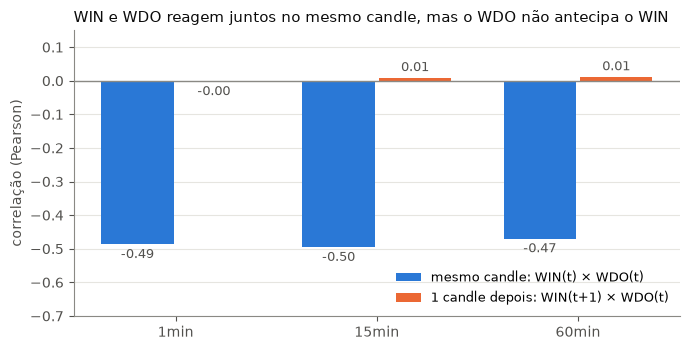

In [8]:
AZUL, LARANJA, CINZA, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.titlecolor": TINTA, "font.size": 10})

corr = []
for c in t.CANDLES:
    d, _ = t.montar_base(win, wdo, c)
    d = d[(d.index >= t.VALIDACAO[0]) & (d.index < t.VALIDACAO[1])]
    corr.append(dict(candle=c, contemporanea=d.ret.corr(d.ret_wdo), defasada=d.alvo.corr(d.ret_wdo_lag1)))
corr = pd.DataFrame(corr).set_index("candle")
display(corr.round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
x, w = np.arange(len(corr)), 0.36
for k, (col, cor, rot) in enumerate([("contemporanea", AZUL, "mesmo candle: WIN(t) × WDO(t)"),
                                     ("defasada", LARANJA, "1 candle depois: WIN(t+1) × WDO(t)")]):
    b = ax.bar(x + (k - 0.5) * (w + 0.02), corr[col], w, color=cor, label=rot)
    ax.bar_label(b, fmt="%.2f", padding=3, color=TINTA2, fontsize=9)
ax.axhline(0, color=CINZA, lw=1)
ax.set_xticks(x, corr.index); ax.set_ylabel("correlação (Pearson)")
ax.set_ylim(min(-0.7, corr.values.min() - 0.12), 0.15)
ax.set_title("WIN e WDO reagem juntos no mesmo candle, mas o WDO não antecipa o WIN", loc="left", fontsize=10.5)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{SAIDA}/correlacao_win_wdo.png", dpi=150); plt.show()

### Há sazonalidade intradiária no retorno?

Autocorrelação do alvo na defasagem 1 (o que o ARIMA explora) e na defasagem de 1 pregão (o que o termo
sazonal explora), comparada à do **valor absoluto** do retorno (volatilidade). Validação 2024.

In [9]:
def acf_lag(x, k):
    return pd.Series(x).autocorr(k)
d = df_s[(df_s.index >= t.VALIDACAO[0]) & (df_s.index < t.VALIDACAO[1])]
acf = pd.DataFrame({"retorno": [acf_lag(d.alvo.values, 1), acf_lag(d.alvo.values, s_ef), acf_lag(d.alvo.values, s_plano)],
                    "|retorno|": [acf_lag(d.alvo.abs().values, 1), acf_lag(d.alvo.abs().values, s_ef),
                                  acf_lag(d.alvo.abs().values, s_plano)]},
                   index=["defasagem 1", f"defasagem {s_ef} (1 pregão, s efetivo)", f"defasagem {s_plano} (s do plano)"])
print(f"{CANDLE_S}, n = {len(d)}; banda de 95% para ruído branco ≈ ±{1.96 / np.sqrt(len(d)):.3f}")
acf.round(3)

60min, n = 2254; banda de 95% para ruído branco ≈ ±0.041


,retorno,|retorno|
defasagem 1,-0.022,0.090
"defasagem 9 (1 pregão, s efetivo)",-0.009,0.149
defasagem 10 (s do plano),0.020,0.044


**Leitura das variantes**

- **WDO como exógena.** A correlação WIN × WDO é forte e negativa no mesmo candle (−0,47 a −0,50) e **≈ 0 com 1 candle de defasagem**, nos três tamanhos de candle. O WDO em *t* não carrega informação sobre o WIN em *t+1*: a reação entre os dois é instantânea. Por isso a ARIMAX **piora** a previsão (Theil U 1,0016 → 1,0043; acurácia 50,2% → 48,5%), o que bate com o teste exploratório da Ana Beatriz.
- **Sazonalidade.** A autocorrelação do retorno na defasagem de 1 pregão é −0,009, dentro da banda de ruído (±0,041). A do **|retorno|** é 0,149, bem fora dela. A sazonalidade intradiária existe, mas está na **volatilidade** (a abertura é sempre mais agitada), não na direção. O SARIMA/SARIMAX modela a média, então não tem o que explorar (SARIMA: Theil U 1,0018 ≈ ARIMA). Para usar esse padrão, o caminho seria um modelo de volatilidade (por exemplo, GARCH com componente intradiária) dimensionando TP/SL, não a direção.
- **Período sazonal.** O |retorno| tem autocorrelação de 0,149 na defasagem 9 (`s` efetivo) contra 0,044 na defasagem 10 (`s` do plano). Isso confirma que, na série com o último candle do dia removido, o "mesmo horário de ontem" fica 9 linhas atrás, não 10.
- **Por que a ARIMAX foi escolhida.** Pela regra fixada antes do teste, ela teve a maior esperança com a melhor regra (+10,2 pts/op). O erro-padrão, porém, é ≈ 18,5 pts. A vantagem sobre o ARIMA (+1,4) é ruído de seleção entre 5 modelos × 36 regras, e a própria ARIMAX tem Theil U pior. Seguimos o protocolo e não trocamos o modelo, com a expectativa registrada aqui de que essa vantagem não se sustente no teste.

### Modelo final da frente (decisão pela regra definida acima)

**Onde fica cada conjunto de regras.** Pela convenção comum, `regras_val.csv` traz as 36 regras do **modelo base**
(ARIMA), calculadas na Etapa C; a frente de ML faz o mesmo. Se o modelo final for uma variante, as 36 regras dela
são salvas em `regras_val_{modelo}_{candle}_{janela}m.csv`. A regra adotada é a 1ª linha desse arquivo, a mesma
gravada no `config_final.json`.

In [10]:
var_ord = var.assign(_base=(var.modelo == "arima").astype(int)) \
             .sort_values(["regra_esperanca_pts", "_base"], ascending=[False, False])
final = var_ord.iloc[0]
MODELO_F, CANDLE_F, JANELA_F = final.modelo, final.candle, int(final.janela_meses)
regras_f = regras_por_modelo[(MODELO_F, CANDLE_F, JANELA_F)]
if (MODELO_F, CANDLE_F, JANELA_F) != (MODELO, CANDLE, JANELA):
    regras_f.to_csv(f"{SAIDA}/regras_val_{MODELO_F}_{CANDLE_F}_{JANELA_F}m.csv", index=False)
regra_f = regras_f.iloc[0]

def fabrica_por_nome(nome):
    if nome == "arima":   return ArimaT1, LAGS
    if nome == "arimax":  return (lambda: ArimaT1(usa_x=True)), X_WDO
    k = int(nome.split("_s")[1])
    if nome.startswith("sarimax"): return (lambda: ArimaT1(seasonal_order=(1, 0, 0, k), usa_x=True)), X_WDO
    return (lambda: ArimaT1(seasonal_order=(1, 0, 0, k))), LAGS
FABRICA_F, FEATS_F = fabrica_por_nome(MODELO_F)
print(f"Modelo final: {MODELO_F} | candle {CANDLE_F} | janela {JANELA_F}m | regra: limiar q={regra_f.limiar_q}, "
      f"TP={regra_f.tp_mult}, SL={regra_f.sl_mult} | esperança na validação {regra_f.esperanca_pts:.2f} pts/op")

Modelo final: arimax | candle 60min | janela 6m | regra: limiar q=0.9, TP=1.0, SL=nan | esperança na validação 10.22 pts/op


## Etapa E – Congelar e rodar o teste (uma vez)

A partir daqui nada é ajustado. O teste (01/01/2025 → 31/03/2026) roda com as escolhas acima.

In [11]:
nan2none = lambda v: None if pd.isna(v) else float(v)
config = dict(frente=FRENTE, modelo=MODELO_F, modelo_base=MODELO, candle=CANDLE_F, janela_meses=JANELA_F,
              order=[1, 0, 1], seasonal_order=list(FABRICA_F().kw["seasonal_order"]), exogena=FEATS_F if FEATS_F == X_WDO else None,
              limiar_q=float(regra_f.limiar_q), limiar=float(regra_f.limiar),
              tp_mult=nan2none(regra_f.tp_mult), sl_mult=nan2none(regra_f.sl_mult),
              validacao=list(t.VALIDACAO), teste=list(t.TESTE), custo_escolha_pts=5)
json.dump(config, open(f"{SAIDA}/config_final.json", "w"), indent=2, default=str)

df_f, _ = t.montar_base(win, wdo, CANDLE_F)
t0 = time.time()
prev_teste = t.walk_forward(df_f, FEATS_F, FABRICA_F, *t.TESTE, janela_meses=JANELA_F)
print(f"teste: {len(prev_teste)} previsões em {time.time() - t0:.0f}s")
prev_teste.to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE_F}_{JANELA_F}m_{MODELO_F}_teste.csv")

tp, sl = config["tp_mult"], config["sl_mult"]
linhas = []
sem_esp = lambda d: {k: v for k, v in d.items() if k != "esperanca_pts"}
for custo in t.CUSTOS_PTS:
    ops_m = t.simular(prev_teste, regra_f.limiar, tp, sl, custo)
    ops_a = t.simular(t.sinais_aleatorios(prev_teste), 0, tp, sl, custo)
    linhas.append(dict(serie="modelo", custo_pts=custo, **t.metricas(prev_teste),
                       **t.resumo_operacoes(ops_m), **sem_esp(estat(ops_m))))
    linhas.append(dict(serie="aleatorio", custo_pts=custo, **t.resumo_operacoes(ops_a), **sem_esp(estat(ops_a))))
teste = pd.DataFrame(linhas)
teste.to_csv(f"{SAIDA}/teste_final.csv", index=False)
teste.round(4)

teste: 2791 previsões em 2s


,serie,custo_pts,n,RMSE,MAE,TheilU,R2_oos,acc_dir,corr,n_ops,...,ganho_medio,perda_media,payoff,esperanca_pts,fator_lucro,resultado_pts,resultado_R,drawdown_max_pts,ep_pts,t_stat
0,modelo,0,2791.0,0.2885,0.1942,1.0027,-0.0053,0.4915,-0.018,214,...,396.6535,-516.4356,0.7681,-36.1440,0.8517,-7734.8069,-1546.9614,13500.4684,41.7464,-0.8658
1,aleatorio,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2791,...,245.8738,-294.2357,0.8356,-13.0565,0.9067,-36440.7987,-7288.1597,48100.2257,7.1119,-1.8359
2,modelo,5,2791.0,0.2885,0.1942,1.0027,-0.0053,0.4915,-0.018,214,...,391.6535,-516.3725,0.7585,-41.1440,0.8328,-8804.8069,-1760.9614,14355.4684,41.7464,-0.9856
3,aleatorio,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2791,...,243.9207,-294.4407,0.8284,-18.0565,0.8732,-50395.7987,-10079.1597,56318.0386,7.1119,-2.5389
4,modelo,10,2791.0,0.2885,0.1942,1.0027,-0.0053,0.4915,-0.018,214,...,386.6535,-521.3725,0.7416,-46.1440,0.8143,-9874.8069,-1974.9614,15210.4684,41.7464,-1.1053
5,aleatorio,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2791,...,243.8911,-295.5665,0.8252,-23.0565,0.8408,-64350.7987,-12870.1597,69318.0386,7.1119,-3.2420


## Etapa F – Gráficos finais e resumo

esperança no teste (custo 5): -41.14 ± 41.7 pts/op (erro-padrão)


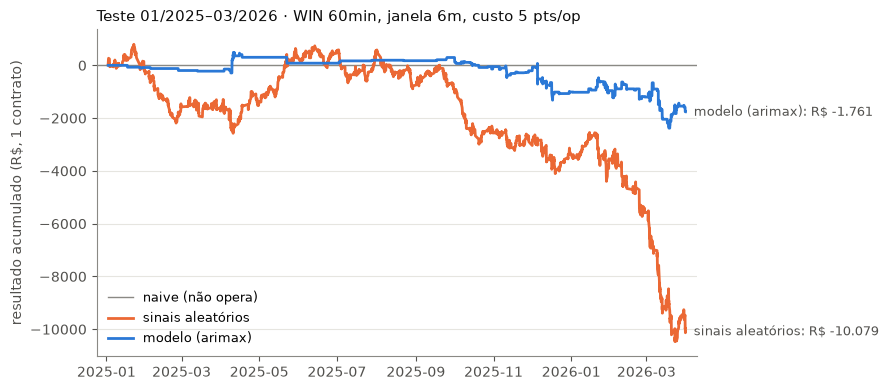

In [12]:
ops_m = t.simular(prev_teste, regra_f.limiar, tp, sl, 5)
_o = ops_m[ops_m.lado != 0].pontos
EP_TESTE = _o.std() / np.sqrt(len(_o))
print(f"esperança no teste (custo 5): {_o.mean():.2f} ± {EP_TESTE:.1f} pts/op (erro-padrão)")
ops_a = t.simular(t.sinais_aleatorios(prev_teste), 0, tp, sl, 5)
cap_m, cap_a = ops_m.pontos.cumsum() * t.PONTO_WIN, ops_a.pontos.cumsum() * t.PONTO_WIN

fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(0, color=CINZA, lw=1, label="naive (não opera)")
for serie, cor, rot in [(cap_a, LARANJA, "sinais aleatórios"), (cap_m, AZUL, f"modelo ({MODELO_F})")]:
    ax.plot(serie.index, serie.values, color=cor, lw=2, label=rot)
    ax.annotate(f"{rot}: R$ {serie.iloc[-1]:,.0f}".replace(",", "."), (serie.index[-1], serie.iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA2)
ax.set_ylabel("resultado acumulado (R$, 1 contrato)")
ax.set_title(f"Teste 01/2025–03/2026 · WIN {CANDLE_F}, janela {JANELA_F}m, custo 5 pts/op", loc="left", fontsize=10.5)
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.margins(x=0.02)
fig.tight_layout(); fig.subplots_adjust(right=0.78)
fig.savefig(f"{SAIDA}/curva_capital_teste.png", dpi=150); plt.show()

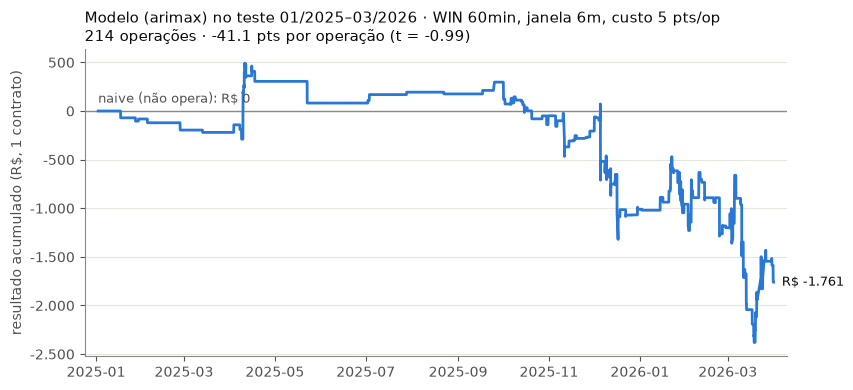

In [13]:
# Versão para o slide: só o modelo (o protocolo continua em curva_capital_teste.png, com os sinais aleatórios)
_o = ops_m[ops_m.lado != 0].pontos
fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(0, color=CINZA, lw=1)
ax.annotate("naive (não opera): R$ 0", (cap_m.index[0], 0), xytext=(0, 6), textcoords="offset points",
            fontsize=9, color=TINTA2)
ax.plot(cap_m.index, cap_m.values, color=AZUL, lw=2)
ax.annotate(f"R$ {cap_m.iloc[-1]:,.0f}".replace(",", "."), (cap_m.index[-1], cap_m.iloc[-1]),
            xytext=(6, 0), textcoords="offset points", va="center", fontsize=9.5, color=TINTA)
ax.set_ylabel("resultado acumulado (R$, 1 contrato)")
ax.set_title(f"Modelo ({MODELO_F}) no teste 01/2025–03/2026 · WIN {CANDLE_F}, janela {JANELA_F}m, custo 5 pts/op\n"
             f"{len(_o)} operações · {_o.mean():.1f} pts por operação (t = {_o.mean() / EP_TESTE:.2f})",
             loc="left", fontsize=10.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.margins(x=0.02)
fig.tight_layout(); fig.subplots_adjust(right=0.88)
fig.savefig(f"{SAIDA}/curva_capital_teste_modelo.png", dpi=150); plt.show()

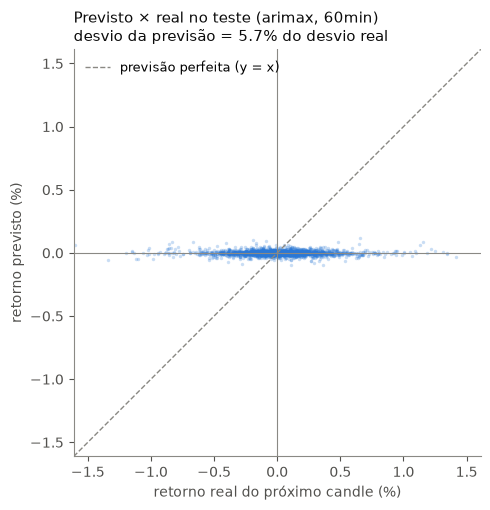

In [14]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(prev_teste.y_true, prev_teste.y_pred, s=6, color=AZUL, alpha=0.25, linewidths=0)
lim = np.quantile(np.abs(prev_teste.y_true), 0.999)
ax.plot([-lim, lim], [-lim, lim], color=CINZA, lw=1, ls="--", label="previsão perfeita (y = x)")
ax.axhline(0, color=CINZA, lw=0.8); ax.axvline(0, color=CINZA, lw=0.8)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
ax.set_xlabel("retorno real do próximo candle (%)"); ax.set_ylabel("retorno previsto (%)")
razao = prev_teste.y_pred.std() / prev_teste.y_true.std()
ax.set_title(f"Previsto × real no teste ({MODELO_F}, {CANDLE_F})\n"
             f"desvio da previsão = {razao:.1%} do desvio real", loc="left", fontsize=10.5)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(f"{SAIDA}/previsto_vs_real_teste.png", dpi=150); plt.show()

### `resumo.md` (5 linhas, Seção 4 – Etapa F)

In [15]:
tm = teste[teste.serie == "modelo"].set_index("custo_pts")
ta = teste[teste.serie == "aleatorio"].set_index("custo_pts")
m0 = tm.iloc[0]
fmt_r = lambda v: f"R$ {v:,.0f}".replace(",", ".")
def regra_txt(r):
    tp_ = "sem TP" if pd.isna(r.tp_mult) else f"TP {r.tp_mult:g}×vol"
    sl_ = "sem stop" if pd.isna(r.sl_mult) else f"SL {r.sl_mult:g}×vol"
    lim_ = "opera sempre" if r.limiar_q == 0 else f"limiar no quantil {r.limiar_q:.0%} de |previsão|"
    return f"{lim_}, {tp_}, {sl_}"

bate = (m0.TheilU < 1) and (m0.R2_oos > 0)
rho_grade = tab.acc_dir.corr(tab.sim_esperanca_pts, method="spearman")
rho_regra = regras.taxa_acerto.corr(regras.esperanca_pts, method="spearman")
var_txt = "; ".join(f"{r.modelo} {r.regra_esperanca_pts:.2f}" for r in var.itertuples())
lucr = [c for c in t.CUSTOS_PTS if tm.loc[c, "esperanca_pts"] > 0 and tm.loc[c, "fator_lucro"] > 1]

linhas_resumo = [
    f"- **Q1 – Candle e janela:** a melhor combinação do ARIMA(1,0,1) na validação 2024 foi candle de {CANDLE} com janela de "
    f"{JANELA} meses (esperança {melhor.sim_esperanca_pts:.2f} pts/op operando sempre, Theil U {melhor.TheilU:.4f}); "
    f"o modelo final da frente, escolhido pela esperança com a melhor regra na validação, foi **{MODELO_F}** em {CANDLE_F} × {JANELA_F}m "
    f"(esperança na validação por variante, pts/op: {var_txt}).",
    f"- **Q2 – Bate o naive?** {'Sim' if bate else 'Não'}: no teste, Theil U = {m0.TheilU:.4f} e R²_oos = {m0.R2_oos:.5f} "
    f"({'abaixo de 1 e positivo' if bate else 'o erro é praticamente igual ao de prever retorno zero'}); "
    f"na validação, {(tab.TheilU < 1).sum()} de 12 combinações tiveram Theil U < 1. A previsão fica colada em zero "
    f"(desvio = {razao:.1%} do desvio do retorno real): o retorno T+1 do WIN não tem estrutura linear que o ARIMA consiga explorar.",
    f"- **Q3 – Acertar mais é ganhar mais?** Acurácia direcional no teste de {m0.acc_dir:.1%} e taxa de acerto das operações de "
    f"{tm.loc[5, 'taxa_acerto']:.1%} (custo 5 pts), com esperança de {tm.loc[5, 'esperanca_pts']:.2f} pts/op; na validação, a correlação "
    f"de Spearman entre taxa de acerto e esperança nas 36 regras foi {rho_regra:.2f} e entre acurácia e esperança nas 12 combinações foi {rho_grade:.2f}.",
    f"- **Q4 – Regra e teste:** regra escolhida na validação: {regra_txt(regra_f)}. No teste, esperança por operação de "
    + ", ".join(f"{tm.loc[c, 'esperanca_pts']:.2f} pts (custo {c})" for c in t.CUSTOS_PTS)
    + f" (erro-padrão ≈ {EP_TESTE:.0f} pts), fator de lucro {tm.loc[5, 'fator_lucro']:.3f} e resultado {fmt_r(tm.loc[5, 'resultado_R'])} com custo 5 em "
    f"{int(tm.loc[5, 'n_ops'])} operações (aleatório: {ta.loc[5, 'esperanca_pts']:.2f} pts/op, {fmt_r(ta.loc[5, 'resultado_R'])} em "
    f"{int(ta.loc[5, 'n_ops'])} operações: perde menos em R$ só porque opera menos); "
    + (f"lucrativa (esperança > 0 e fator > 1) com custo {', '.join(map(str, lucr))} pts." if lucr else "não é lucrativa em nenhum custo."),
    f"- **Limitação/surpresa:** o WDO não antecipa o WIN: a reação entre os dois é instantânea "
    f"(correlação no mesmo candle {corr.loc[CANDLE_S, 'contemporanea']:.2f} contra {corr.loc[CANDLE_S, 'defasada']:.3f} com 1 candle de defasagem, em {CANDLE_S}), "
    f"e a ARIMAX piorou o Theil U. Ela venceu na validação ({final.regra_esperanca_pts:+.1f} ± {final.regra_ep_pts:.1f} pts/op) por ruído, "
    f"e isso não se repetiu no teste. A sazonalidade intradiária existe na volatilidade (|retorno|), não na direção, "
    f"por isso o SARIMA/SARIMAX (que modela a média) não ganhou nada.",
]
Path(f"{SAIDA}/resumo.md").write_text("# Resumo – frente estatística (ARIMA / ARIMAX / SARIMAX)\n\n" + "\n".join(linhas_resumo) + "\n")
print(Path(f"{SAIDA}/resumo.md").read_text())

# Resumo – frente estatística (ARIMA / ARIMAX / SARIMAX)

- **Q1 – Candle e janela:** a melhor combinação do ARIMA(1,0,1) na validação 2024 foi candle de 60min com janela de 6 meses (esperança -1.44 pts/op operando sempre, Theil U 1.0016); o modelo final da frente, escolhido pela esperança com a melhor regra na validação, foi **arimax** em 60min × 6m (esperança na validação por variante, pts/op: arima 1.39; arimax 10.22; sarima_s9 -0.72; sarimax_s10 5.93; sarimax_s9 3.77).
- **Q2 – Bate o naive?** Não: no teste, Theil U = 1.0027 e R²_oos = -0.00533 (o erro é praticamente igual ao de prever retorno zero); na validação, 0 de 12 combinações tiveram Theil U < 1. A previsão fica colada em zero (desvio = 5.7% do desvio do retorno real): o retorno T+1 do WIN não tem estrutura linear que o ARIMA consiga explorar.
- **Q3 – Acertar mais é ganhar mais?** Acurácia direcional no teste de 49.2% e taxa de acerto das operações de 52.3% (custo 5 pts), com esperança de -41.14 pts/op; na validação, a cor

**Leitura do teste (rodado uma vez)**

- **Q2:** Theil U 1,0027 e R²_oos −0,005, ou seja, **não bate o naive**. A dispersão mostra a previsão achatada em zero (desvio de 5,7% do real): o modelo praticamente não prevê magnitude.
- **Q4:** com a regra congelada (limiar 90%, TP 1×, sem stop), a esperança é **−41 pts/op** com custo de 5 pts (−36 mesmo com custo zero) e o fator de lucro é 0,83. A regra **não é lucrativa em nenhum custo**. O erro-padrão (≈ 42 pts) é do mesmo tamanho da média: o resultado é consistente com **ausência de vantagem**, e os +10 pts da validação foram ruído de seleção, como antecipado na Etapa D.
- **Contra o aleatório:** em R$ o modelo perde menos (R$ −1.761 contra R$ −10.079), mas só porque opera 13× menos (214 contra 2.791 operações). **Por operação** ele perde mais (−41 contra −18 pts). A comparação justa é a por operação, e nela o modelo não ganha de jogar moeda.
- **Q3:** a taxa de acerto das operações é de 52,3% (mais da metade) e mesmo assim a esperança é negativa. O payoff é 0,76: o TP de 1× corta os ganhos e, sem stop, as perdas correm (perda média de 516 pts contra ganho médio de 392 pts). É exatamente a lição do outro grupo: acertar mais não é ganhar mais.
- **Conclusão da frente:** a família ARIMA (com ou sem WDO, com ou sem sazonalidade) não encontra estrutura linear explorável no retorno T+1 do WIN em nenhum tamanho de candle. O resultado é consistente com um mercado eficiente nessa escala. O padrão que existe (volatilidade intradiária) é de risco, não de direção.

## Etapa G (extra) – O que o modelo estimou e as bandas de previsão

Análise descritiva, feita depois do teste e **sem mudar nenhuma escolha congelada**. Responde a duas perguntas:

1. **Que parâmetros o modelo estimou?** Em cada trimestre: o coeficiente AR (φ), o MA (θ), o efeito do WDO (β) e a variância do ruído (σ²).
2. **As bandas do SARIMAX servem para dizer "até onde o preço pode ir"?** Além da previsão pontual (o retorno esperado), o SARIMAX
   devolve um **intervalo de previsão**: `get_prediction().conf_int()`. Se o modelo estiver bem especificado, o retorno real
   cai dentro da banda de 95% em 95% das vezes. Conferimos isso no total e por horário do pregão.

O retorno previsto e a banda viram preço por `P̂(t+1) = P(t)·exp(r̂/100)`.

In [16]:
def wf_bandas(inicio, fim):
    '''Mesmo walk-forward do t.walk_forward (mesmos cortes, janela e embargo), guardando também os
    intervalos de previsão e os parâmetros estimados em cada trimestre.'''
    cortes = sorted(set(list(pd.date_range(inicio, fim, freq=t.RETREINO)) + [pd.Timestamp(fim)]))
    blocos, pars = [], []
    for ini, fb in zip(cortes[:-1], cortes[1:]):
        tr = df_f[(df_f.index >= ini - pd.DateOffset(months=JANELA_F)) & (df_f.index < ini)].iloc[:-1]
        te = df_f[(df_f.index >= ini) & (df_f.index < fb)]
        if te.empty or tr.empty:
            continue
        m = FABRICA_F().fit(tr[FEATS_F], tr["alvo"])
        pr = m.res.extend(te["alvo"].values, exog=te[FEATS_F].values if m.usa_x else None).get_prediction()
        c95, c80 = pr.conf_int(alpha=0.05), pr.conf_int(alpha=0.20)
        blocos.append(pd.DataFrame({"y_true": te["alvo"], "y_pred": pr.predicted_mean, "lo95": c95[:, 0], "hi95": c95[:, 1],
                                    "lo80": c80[:, 0], "hi80": c80[:, 1], "close": te["close"], "close_prox": te["close_prox"]},
                                   index=te.index))
        nomes = m.res.model.param_names
        pars.append(dict(trimestre=f"{ini:%Y-%m}", n_treino=len(tr),
                         **{f"{k}": v for k, v in zip(nomes, m.res.params)},
                         **{f"p_{k}": v for k, v in zip(nomes, m.res.pvalues) if k != "sigma2"}))
    return pd.concat(blocos), pd.DataFrame(pars)

band_val, par_val = wf_bandas(*t.VALIDACAO)
band_te, par_te = wf_bandas(*t.TESTE)
assert np.allclose(band_te.y_pred.values, prev_teste.y_pred.values), "bandas fora de sincronia com o teste"
par = pd.concat([par_val.assign(periodo="validação"), par_te.assign(periodo="teste")])
par = par.rename(columns={"x1": "beta_wdo", "p_x1": "p_beta_wdo", "ar.L1": "phi_ar", "p_ar.L1": "p_phi_ar",
                          "ma.L1": "theta_ma", "p_ma.L1": "p_theta_ma"})
par.to_csv(f"{SAIDA}/parametros_estimados.csv", index=False)
par.round(4)

,trimestre,n_treino,beta_wdo,phi_ar,theta_ma,sigma2,p_beta_wdo,p_phi_ar,p_theta_ma,periodo
0,2024-01,429,-0.1174,0.2868,-0.2580,0.0632,0.1197,0.8871,0.8992,validação
1,2024-04,974,-0.1358,0.8927,-0.8875,0.0560,0.0027,0.1551,0.1680,validação
2,2024-07,1111,-0.0587,-0.1394,0.0946,0.0562,0.3211,0.8385,0.8912,validação
3,2024-10,1159,0.0623,0.6528,-0.6232,0.0494,0.1181,0.1435,0.1767,validação
0,2025-01,1141,0.0095,-0.6485,0.6177,0.0484,0.7640,0.0725,0.0982,teste
1,2025-04,1093,0.0090,-0.9604,0.9483,0.0624,0.7973,0.0000,0.0000,teste
2,2025-07,1093,-0.0067,0.0040,-0.0424,0.0832,0.8710,0.9954,0.9519,teste
3,2025-10,1142,-0.0663,-0.1443,0.0426,0.0788,0.1027,0.5969,0.8789,teste
4,2026-01,1151,0.0208,0.5607,-0.5004,0.0606,0.6388,0.0498,0.0999,teste


In [17]:
for nome, b in [("validação", band_val), ("teste", band_te)]:
    c95 = ((b.y_true >= b.lo95) & (b.y_true <= b.hi95)).mean()
    c80 = ((b.y_true >= b.lo80) & (b.y_true <= b.hi80)).mean()
    meia = (b.hi95 - b.lo95) / 2
    print(f"{nome:>9}: cobertura da banda de 95% = {c95:.1%} | de 80% = {c80:.1%} | meia-largura 95% = ±{meia.median():.2f}% "
          f"≈ ±{(meia / 100 * b.close).median():.0f} pts | desvio da previsão pontual = {b.y_pred.std():.3f}% contra "
          f"{b.y_true.std():.3f}% do retorno real")

b = band_te.assign(hora_alvo=band_te.index.hour + 1,                        # a linha de t prevê o candle seguinte (t+1h)
                   dentro=lambda d: (d.y_true >= d.lo95) & (d.y_true <= d.hi95),
                   meia95=lambda d: (d.hi95 - d.lo95) / 2)
por_hora = b.groupby("hora_alvo").agg(n=("y_true", "size"), cobertura_95=("dentro", "mean"),
                                      desvio_real=("y_true", "std"),
                                      faixa_real_95=("y_true", lambda s: s.abs().quantile(0.95)),
                                      meia_banda_95=("meia95", "mean"))
por_hora.to_csv(f"{SAIDA}/bandas_por_hora_teste.csv")
por_hora.round(3)

validação: cobertura da banda de 95% = 95.0% | de 80% = 85.9% | meia-largura 95% = ±0.46% ≈ ±595 pts | desvio da previsão pontual = 0.018% contra 0.229% do retorno real
    teste: cobertura da banda de 95% = 92.2% | de 80% = 82.0% | meia-largura 95% = ±0.49% ≈ ±785 pts | desvio da previsão pontual = 0.016% contra 0.288% do retorno real


,n,cobertura_95,desvio_real,faixa_real_95,meia_banda_95
hora_alvo,,,,,
10,309,0.738,0.469,0.933,0.505
11,309,0.832,0.391,0.822,0.505
12,309,0.906,0.304,0.609,0.505
13,309,0.958,0.215,0.433,0.505
14,311,0.968,0.279,0.446,0.505
15,311,0.955,0.246,0.467,0.505
16,311,0.981,0.190,0.388,0.505
17,311,0.971,0.190,0.435,0.505
18,311,0.987,0.157,0.238,0.505


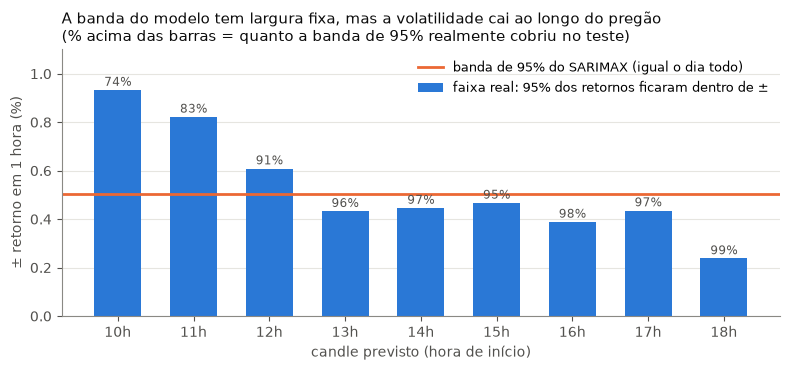

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(por_hora))
bars = ax.bar(x, por_hora.faixa_real_95, 0.62, color=AZUL, label="faixa real: 95% dos retornos ficaram dentro de ±")
ax.axhline(por_hora.meia_banda_95.mean(), color=LARANJA, lw=2, label="banda de 95% do SARIMAX (igual o dia todo)")
for xi, (fr, cob) in enumerate(zip(por_hora.faixa_real_95, por_hora.cobertura_95)):
    ax.annotate(f"{cob:.0%}", (xi, fr), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, color=TINTA2)
ax.set_xticks(x, [f"{h}h" for h in por_hora.index]); ax.set_xlabel("candle previsto (hora de início)")
ax.set_ylabel("± retorno em 1 hora (%)")
ax.set_title("A banda do modelo tem largura fixa, mas a volatilidade cai ao longo do pregão\n"
             "(% acima das barras = quanto a banda de 95% realmente cobriu no teste)", loc="left", fontsize=10.5)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_ylim(0, por_hora.faixa_real_95.max() * 1.18)
fig.tight_layout(); fig.savefig(f"{SAIDA}/bandas_por_hora_teste.png", dpi=150); plt.show()

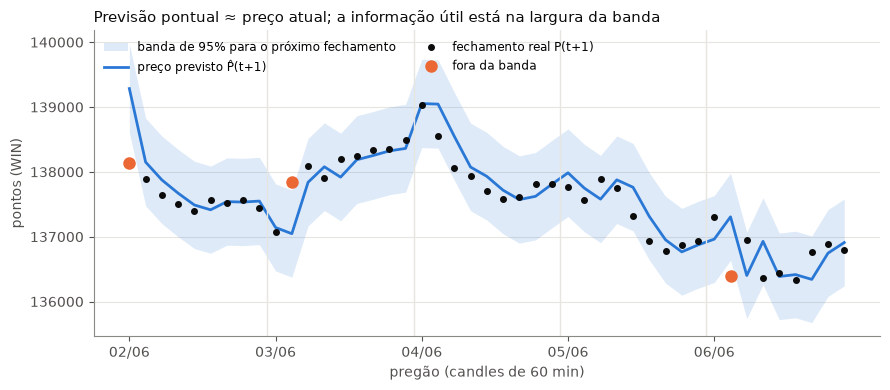

In [19]:
# Exemplo em preço: uma semana do teste, candle a candle (sem os buracos da noite)
sem = band_te.loc["2025-06-02":"2025-06-06"].copy()
p_prev = sem.close * np.exp(sem.y_pred / 100)
lo, hi = sem.close * np.exp(sem.lo95 / 100), sem.close * np.exp(sem.hi95 / 100)
xi = np.arange(len(sem))
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(xi, lo, hi, color=AZUL, alpha=0.15, lw=0, label="banda de 95% para o próximo fechamento")
ax.plot(xi, p_prev, color=AZUL, lw=2, label="preço previsto P̂(t+1)")
ax.plot(xi, sem.close_prox, color=TINTA, lw=0, marker="o", ms=4, label="fechamento real P(t+1)")
fora = (sem.close_prox < lo) | (sem.close_prox > hi)
ax.plot(xi[fora], sem.close_prox[fora], color=LARANJA, lw=0, marker="o", ms=8, label="fora da banda")
dias = pd.Series(sem.index.date)
ini_dia = dias.ne(dias.shift()).to_numpy().nonzero()[0]
ax.set_xticks(ini_dia, [f"{d:%d/%m}" for d in dias.iloc[ini_dia]])
for k in ini_dia[1:]:
    ax.axvline(k - 0.5, color="#e6e5e0", lw=1)
ax.set_ylabel("pontos (WIN)"); ax.set_xlabel("pregão (candles de 60 min)")
ax.set_title("Previsão pontual ≈ preço atual; a informação útil está na largura da banda", loc="left", fontsize=10.5)
ax.legend(frameon=False, loc="upper left", fontsize=8.5, ncol=2)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{SAIDA}/bandas_exemplo_semana.png", dpi=150); plt.show()

**Leitura**

- **O ARMA(1,1) quase se anula.** Na maioria dos trimestres φ e θ têm sinais opostos e tamanhos parecidos. Nesse caso (1 − φB) e (1 + θB) praticamente se cancelam, e o modelo fica equivalente a ruído branco: prever retorno ≈ 0. O β do WDO não é significativo (p-valor alto) na maior parte dos trimestres. Isso explica, pelos próprios parâmetros, por que a previsão pontual fica colada em zero.
- **As bandas existem e, no total, são razoáveis.** A de 95% cobre ~95% na validação e ~92% no teste, com meia-largura de ≈ ±0,49% (≈ ±785 pts) por hora. A banda responde a "**até onde** o preço pode ir": isso é medida de risco. Já "**quanto** vai subir ou descer" é a previsão pontual, que aqui é ≈ 0 e cerca de 30× menor que a banda.
- **A banda é a mesma o dia todo, mas o risco não é.** O SARIMAX assume variância constante (σ² fixo dentro do trimestre). No candle das 10h a banda cobre só ~74%: a volatilidade real é quase 2× a banda. Nos candles da tarde (13h–18h) ela cobre ~96–99%: a banda é larga demais. É a mesma sazonalidade do |retorno| vista na Etapa D.
- **Consequência prática.** Para usar as bandas como TP/SL ou como gestão de risco, elas precisariam variar com o horário. Isso pede um modelo de volatilidade (GARCH, ou uma volatilidade por horário), não um modelo da média.

## Checklist da Seção 5

In [20]:
esperados = ["grade_val.csv", "heatmap_theilU.png", "heatmap_acuracia.png", "heatmap_esperanca.png", "regras_val.csv",
             "variante_val.csv", "config_final.json", "teste_final.csv", "curva_capital_teste.png",
             "previsto_vs_real_teste.png", "resumo.md", "correlacao_win_wdo.png",
             "parametros_estimados.csv", "bandas_por_hora_teste.csv", "bandas_por_hora_teste.png", "bandas_exemplo_semana.png"]
val = sorted(Path(f"{SAIDA}/previsoes").glob(f"WIN_*m_{MODELO}_val.csv"))
tst = sorted(Path(f"{SAIDA}/previsoes").glob("WIN_*_teste.csv"))
for f in esperados:
    print("✔" if Path(f"{SAIDA}/{f}").exists() else "✘", f)
print("✔" if len(val) == 12 else "✘", f"previsões de validação do modelo base: {len(val)} de 12")
print("✔" if len(tst) == 1 else "✘", f"previsão de teste: {len(tst)} arquivo(s)")
print("✔" if len(pd.read_csv(f'{SAIDA}/regras_val.csv')) == 36 else "✘", "regras_val.csv com 36 linhas")

✔ grade_val.csv
✔ heatmap_theilU.png
✔ heatmap_acuracia.png
✔ heatmap_esperanca.png
✔ regras_val.csv
✔ variante_val.csv
✔ config_final.json
✔ teste_final.csv
✔ curva_capital_teste.png
✔ previsto_vs_real_teste.png
✔ resumo.md
✔ correlacao_win_wdo.png
✔ parametros_estimados.csv
✔ bandas_por_hora_teste.csv
✔ bandas_por_hora_teste.png
✔ bandas_exemplo_semana.png
✔ previsões de validação do modelo base: 12 de 12
✔ previsão de teste: 1 arquivo(s)
✔ regras_val.csv com 36 linhas
